# Rama B: efecto de la temperatura en la fluorescencia azul

Este cuaderno repite el análisis de [`fluorescencia.ipynb`](fluorescencia.ipynb) con la celda a 50, 60, 70 y 80 °C y se centra en lo que cambia con la temperatura. La lectura de archivos, el eje de frecuencia absoluto y los modelos de ajuste son los mismos. Las funciones se copian de ese cuaderno para que este se ejecute por sí solo.

La temperatura entra por dos vías:

- **Densidad de átomos:** la presión de vapor del Cs sube muy rápido con T. Con la fórmula de Steck para el Cs líquido, $\log_{10}(P/\mathrm{Torr}) = 7.046 - 3830\,\mathrm{K}/T$, la densidad $n = P/k_BT$ se multiplica por ≈ 2.2, 2.1 y 2.0 en cada paso de 10 °C, es decir ×9.3 entre 50 y 80 °C. Una señal proporcional al número de átomos debería seguir a $n$, y la profundidad óptica de la D2 también es proporcional a $n$.
- **Ancho Doppler:** crece como $\sqrt{T}$, solo un 4.6 % entre 50 y 80 °C.

La temperatura del nombre es la que marca el controlador de la celda. Si el vapor lo fija un punto más frío de la celda, la $n$ real es menor y puede crecer de otra forma.

**Tomas disponibles:**

| Serie | 50 °C | 60 °C | 70 °C | 80 °C |
|---|---|---|---|---|
| 822 solo (45 mW) | ✓ | ✓ | ✓ | ✓ |
| 852 solo, 0.2, 0.5 y 1 mW | ✓ | ✓ | ✓ | ✓ |
| 852 solo, 3.5 mW | ✗ (el 822 estaba encendido) | ✓ | ✓ | ✓ |
| 852 + 822 fijo, 0.2, 0.5 y 1 mW | ✓ | ✓ | ✓ | ✓ |
| 852 + 822 fijo, 3.5 mW | — | ✓ | ✗ (el archivo tiene un barrido del 822) | ✓ |
| 852 solo y 852 + 822 a 5, 10.1 y 14.4 mW | — | — | — | ✓ |

Solo se comparan las potencias que existen en más de una temperatura. La potencia "0.5 mW" es 500 µW a 50, 60 y 70 °C, y 503 µW (852 solo) o 510 µW (852 + 822) a 80 °C.

In [2]:
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

from constants import c, kB, cte

C_LIGHT = c*1e-3  # nm*THz
BASE = '.'

# Estructura hiperfina (THz). 6S y 6P3/2: Steck, "Cesium D Line Data"; 8S1/2: A = 219.125 MHz (Fendel et al. 2007)
HF_6S_F4 = 4.021776399375e-3
HF_6P = {5: 263.81e-6, 4: 12.815e-6, 3: -188.4885e-6}
HF_8S_F4 = 7/4 * 219.125e-6

NU_852 = cte['nu_ba[Hz]']*1e-12 - HF_6S_F4 + HF_6P[5]          # 6S F=4 -> 6P3/2 F'=5
NU_822 = (cte['nu_ca[Hz]']*1e-12 - HF_6S_F4 + HF_8S_F4) / 2    # mitad de 6S F=4 -> 8S F=4
DET_FP = {F: (HF_6P[F] - HF_6P[5])*1e6 for F in (5, 4, 3)}      # F' respecto a F'=5 (MHz)

def doppler_fwhm(nu, T_C):
    # FWHM Doppler (MHz) de un haz a frecuencia nu (THz), átomos a T_C (°C)
    return nu*1e6*np.sqrt(8*kB*(T_C + 273.15)*np.log(2) / (cte['m_Cs[kg]']*c**2))

def n_Cs(T_C):
    # Densidad de Cs (cm^-3) en equilibrio con el líquido: log10(P/Torr) = 2.881 + 4.165 - 3830/T (Steck)
    T = T_C + 273.15
    return 10**(2.881 + 4.165 - 3830/T)*133.322 / (kB*T) * 1e-6

TEMPS = (50.0, 60.0, 70.0, 80.0)
print(f"{'T (°C)':>6s} {'n (cm⁻³)':>10s} {'n/n(50 °C)':>11s} {'Doppler 822 (MHz)':>18s} {'Doppler 852 (MHz)':>18s}")
for T in TEMPS:
    print(f"{T:6.0f} {n_Cs(T):10.2e} {n_Cs(T)/n_Cs(50):11.2f} {doppler_fwhm(NU_822, T):18.1f} {doppler_fwhm(NU_852, T):18.1f}")

# Colores: la temperatura va en una rampa de un solo azul (claro = frío); azul/naranja/aqua para series sin orden
COL_T = {50.0: '#86b6ef', 60.0: '#3987e5', 70.0: '#1c5cab', 80.0: '#0d366b'}
C1, C2, C3, INK, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#8a8984'
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

T (°C)   n (cm⁻³)  n/n(50 °C)  Doppler 822 (MHz)  Doppler 852 (MHz)
    50   4.67e+11        1.00              407.1              392.8
    60   1.03e+12        2.20              413.3              398.8
    70   2.16e+12        4.62              419.5              404.8
    80   4.34e+12        9.30              425.6              410.6


## Lectura de archivos

Las funciones de lectura, corte en rampas y promedio en bins de 10 MHz son las de `fluorescencia.ipynb`. Cada toma se indexa por (serie, potencia nominal, temperatura).

La columna "lejos" es la mediana de las cuentas con ν852 > +450 MHz, fuera de la línea D2. En el 852 solo es el fondo, de 20 a 700 cuentas/s. Con el 822 fijo es la fluorescencia de dos fotones, de 2000 a 11 000 cuentas/s.

**Archivos descartados:**

- **`852-0MHz-3.5mW-46mW-20mHz-200ms-70C.txt`:** no tiene ninguna lectura del 852. El medidor de onda registra λ entre 822.4642 y 822.4695 nm, es decir, un barrido del 822 de ≈ 2.3 GHz con un pico de ≈ 5800 cuentas/s. No queda claro qué láser estaba barriendo ni si el 852 estaba encendido, así que no se usa.
- **`852-3.5mW-20mHz-200ms-50C.txt`:** el nombre dice 852 solo, pero el 822 estaba encendido.
  - Lejos de resonancia tiene ≈ 2300 cuentas/s, el nivel de la fluorescencia de dos fotones a 50 °C (≈ 2500 cuentas/s en el 822 solo y en las tomas 852 + 822 de esa temperatura). Los demás barridos del 852 solo están entre 20 y 700.
  - Tiene la misma forma que el barrido 852 + 822 a 3.5 mW y 60 °C: supresión entre F′=3 y F′=4 y recuperación hacia frecuencias mayores.

  Lo más probable es que sea la toma 852 + 822 a 3.5 mW de 50 °C, que no aparece con su nombre. Como no hay un barrido del 852 solo a 3.5 mW y 50 °C para restarle, no se usa en ninguna sección.

In [3]:
def parse_name(path):
    # <láser>-[<desint. fijo>]-<P barrido>-[<P fijo>]-<frec>-<exp>-<T>.txt
    f = os.path.basename(path)[:-4].split('-')
    def mW(s):
        return float(s[:-3])*1e-3 if s.endswith('muW') else float(s[:-2])
    meta = dict(laser=int(f[0]), T=float(f[-1][:-1]), t_exp=float(f[-2][:-2]), f_bar=float(f[-3][:-3]),
                det_fijo=None, P_fijo=None)
    if len(f) == 7:
        meta.update(det_fijo=float(f[1][:-3]), P=mW(f[2]), P_fijo=mW(f[3]))
    else:
        meta.update(P=mW(f[1]))
    return meta

def load(path):
    # Descarta filas sin lectura válida del láser barrido y las de 0 cuentas
    meta = parse_name(path)
    d = np.loadtxt(path)
    k = (np.abs(d[:, 1] - meta['laser']) < 1) & (d[:, 2] > 0)
    ref = NU_822 if meta['laser'] == 822 else NU_852
    return meta, dict(lam=d[k, 1], A=d[k, 2], det=(d[k, 3] - ref)*1e6, n_desc=int((~k).sum()))

def ramps(lam, w=9, dist=40):
    # Índices de cada rampa del barrido triangular, cortando en los extremos de lambda
    s = uniform_filter1d(lam, w)
    t = np.sort(np.r_[find_peaks(s, distance=dist)[0], find_peaks(-s, distance=dist)[0]])
    edges = np.r_[0, t, len(lam)]
    return [np.arange(a, b) for a, b in zip(edges[:-1], edges[1:]) if b - a > 5]

def average(x, y, segs, bin_w=10.0):
    # Promedia todas las rampas en bins de ancho bin_w (MHz): media y desviación estándar
    idx = np.concatenate(segs)
    xb = np.floor(x[idx]/bin_w)*bin_w + bin_w/2
    ux = np.unique(xb)
    m = np.array([y[idx][xb == u].mean() for u in ux])
    s = np.array([y[idx][xb == u].std() for u in ux])
    return ux, m, s

def scan(path, bin_w=10.0):
    meta, d = load(path)
    segs = ramps(d['lam'])
    x, m, s = average(d['det'], d['A'], segs, bin_w)
    return meta, d, segs, x, m, s

def P_nom(P):
    # 503 y 510 µW (80 °C) se agrupan con 500 µW (60 y 70 °C)
    return 0.5 if abs(P - 0.5) < 0.02 else P

def label(P):
    return f"{P*1e3:.0f} µW" if P < 1 else f"{P:g} mW"

def mark_Fp(ax):
    # Líneas verticales en las transiciones F=4 → F'=3, 4, 5 (átomos con v_z = 0)
    for F, x0 in DET_FP.items():
        ax.axvline(x0, ls='--', lw=0.8, color=GRID)
        ax.annotate(f"F′={F}", (x0, 1), xycoords=('data', 'axes fraction'), xytext=(2, -10),
                    textcoords='offset points', fontsize=8, color=GRID)

files = sorted(f for f in glob.glob(os.path.join(BASE, 'data', '*.txt')) if 'readme' not in f.lower())
# Archivos cuyo contenido no corresponde al nombre (ver el texto de arriba)
EXCLUIR = {'852-3.5mW-20mHz-200ms-50C.txt': 'nivel lejos de resonancia de toma 852 + 822'}
DATA = {}   # (serie, P nominal, T) -> archivo; serie: '822', '852' o '852+822'
print(f"{'archivo':46s} {'serie':>8s} {'T':>4s} {'P (mW)':>7s} {'filas':>6s} {'desc.':>6s} {'rampas':>6s} "
      f"{'rango (MHz)':>15s} {'lejos (c/s)':>12s}")
for f in files:
    meta, d = load(f)
    serie = '822' if meta['laser'] == 822 else '852' if meta['P_fijo'] is None else '852+822'
    if len(d['A']) < 50:
        lam = np.loadtxt(f)[:, 1]
        print(f"{os.path.basename(f):46s} {serie:>8s} {meta['T']:4.0f}  DESCARTADO: sin lecturas del {meta['laser']} "
              f"(λ registrada {lam.min():.4f}…{lam.max():.4f} nm)")
        continue
    # Mediana de las cuentas para ν852 > +450 MHz: fondo del 852 solo, o fluorescencia de dos fotones si el 822 está fijo
    far = np.median(d['A'][d['det'] > 450]) if meta['laser'] == 852 and np.any(d['det'] > 450) else np.nan
    excl = os.path.basename(f) in EXCLUIR
    if not excl:
        DATA[(serie, P_nom(meta['P']), meta['T'])] = f
    print(f"{os.path.basename(f):46s} {serie:>8s} {meta['T']:4.0f} {meta['P']:7.3f} {len(d['A']) + d['n_desc']:6d} "
          f"{d['n_desc']:6d} {len(ramps(d['lam'])):6d} {d['det'].min():7.0f}…{d['det'].max():<5.0f} {far:12.0f}"
          + (f"  DESCARTADO: {EXCLUIR[os.path.basename(f)]}" if excl else ''))

archivo                                           serie    T  P (mW)  filas  desc. rampas     rango (MHz)  lejos (c/s)
822-45mW-20mHz-200ms-50C.txt                        822   50  45.000    312      2      3   -1216…2744           nan
822-45mW-20mHz-200ms-60C.txt                        822   60  45.000    395      2      4   -1525…2347           nan
822-45mW-20mHz-200ms-70C.txt                        822   70  45.000    507      2      5   -2777…1104           nan
822-45mW-20mHz-200ms-80C.txt                        822   80  45.000    656      1      6   -2331…1539           nan
852-0MHz-10.1mW-46mW-20mHz-200ms-80C.txt        852+822   80  10.100    464      1      5    -687…997           9175
852-0MHz-14.42mW-46mW-20mHz-200ms-80C.txt       852+822   80  14.420    793      1      7    -717…951           8520
852-0MHz-1mW-46mW-20mHz-200ms-50C.txt           852+822   50   1.000    405      2      4    -941…715           2438
852-0MHz-1mW-46mW-20mHz-200ms-60C.txt           852+822   60  

## 1. Barrido del 822 solo

El pico de dos fotones 6S F=4 → 8S F=4 con haces copropagantes es un perfil Doppler, así que con la temperatura cambian dos cosas:

- **El ancho:** debería crecer como $\sqrt{T}$, de 407 a 426 MHz.
- **La altura:** si la fluorescencia azul es proporcional al número de átomos en el volumen que ve el PMT, debería crecer como $n$, es decir ×9.3 entre 50 y 80 °C.

Se ajusta una gaussiana más línea base al promedio de rampas, igual que en `fluorescencia.ipynb`. Como el promedio mezcla rampas de subida y de bajada, que están corridas entre sí por la exposición de 200 ms, el ancho también se mide rampa por rampa, usando solo las rampas que cubren el pico completo (±700 MHz alrededor del centro). Ese ancho es el que se compara con el Doppler.

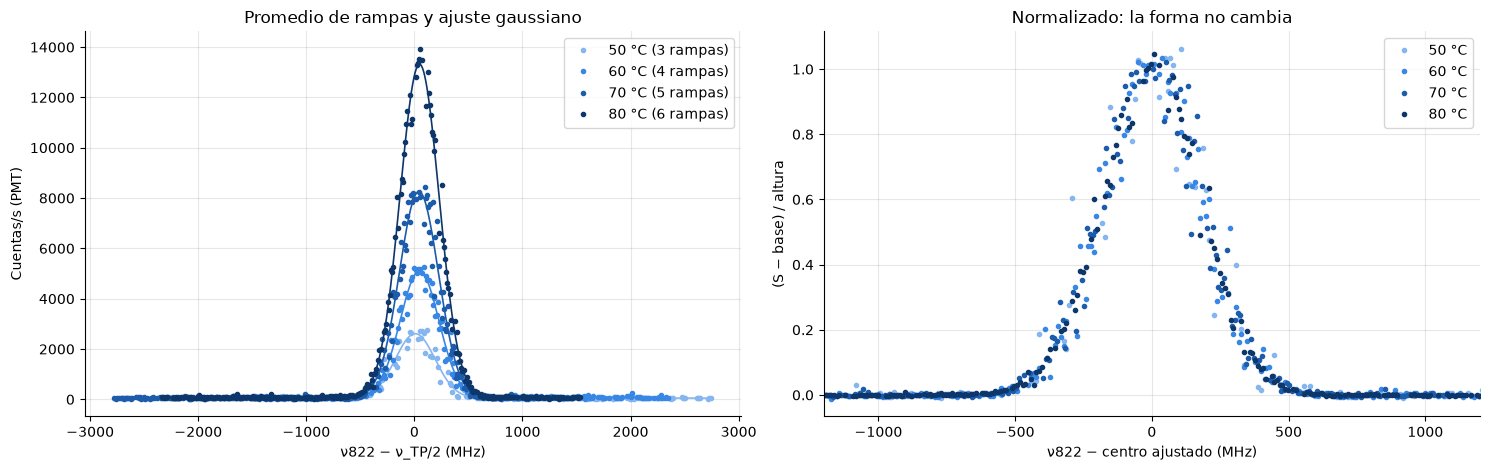

   T  centro (MHz)  FWHM prom.    FWHM por rampa  Doppler  altura (c/s)  área (c/s·GHz)  subida − bajada
  50    7.5 ± 4.3    433 ± 11   404.5 ± 7.5 (N=2)    407.1    2559 ± 49              1.18           73 MHz
  60   47.4 ± 1.8    423 ± 5    419.2 ± 1.3 (N=3)    413.3    5020 ± 46              2.26           62 MHz
  70   41.7 ± 1.8    426 ± 5    420.7 ± 1.7 (N=4)    419.5    8202 ± 75              3.72           66 MHz
  80   47.3 ± 0.9    424 ± 2    421.1 ± 1.9 (N=4)    425.6   13239 ± 62              5.98           20 MHz


In [4]:
def gauss(x, c0, x0, s, a):
    return c0 + a*np.exp(-(x - x0)**2 / (2*s**2))

def fit_gauss(x, y):
    k = np.argmax(uniform_filter1d(y, 5))
    popt, pcov = curve_fit(gauss, x, y, p0=[np.percentile(y, 5), x[k], 150, y[k]], maxfev=20000)
    return popt, np.sqrt(np.diag(pcov))

res822 = {}
fig, (ax, axn) = plt.subplots(1, 2, figsize=(15, 4.8))
for T in TEMPS:
    meta, d, segs, x, m, s = scan(DATA[('822', 45.0, T)])
    popt, perr = fit_gauss(x, m)
    per = []   # (dirección, centro, FWHM) de cada rampa completa
    for sg in segs:
        xr = d['det'][sg]
        if xr.min() < popt[1] - 700 and xr.max() > popt[1] + 700:
            p, _ = fit_gauss(xr, d['A'][sg])
            per.append((np.sign(xr[-1] - xr[0]), p[1], 2.3548*abs(p[2])))
    per = np.array(per)
    res822[T] = dict(x0=popt[1], ex0=perr[1], fwhm=2.3548*abs(popt[2]), efwhm=2.3548*perr[2], a=popt[3], ea=perr[3],
                     c0=popt[0], area=popt[3]*abs(popt[2])*np.sqrt(2*np.pi)*1e-6,
                     fwhm_r=per[:, 2], up=per[per[:, 0] > 0, 1].mean(), dn=per[per[:, 0] < 0, 1].mean())
    xx = np.linspace(x.min(), x.max(), 2000)
    ax.plot(x, m, 'o', ms=3, color=COL_T[T], label=f'{T:g} °C ({len(segs)} rampas)')
    ax.plot(xx, gauss(xx, *popt), '-', color=COL_T[T], lw=1.2)
    axn.plot(x - popt[1], (m - popt[0])/popt[3], 'o', ms=3, color=COL_T[T], label=f'{T:g} °C')
ax.set_xlabel('ν822 − ν_TP/2 (MHz)')
ax.set_ylabel('Cuentas/s (PMT)')
ax.set_title('Promedio de rampas y ajuste gaussiano')
ax.legend()
axn.set_xlim(-1200, 1200)
axn.set_xlabel('ν822 − centro ajustado (MHz)')
axn.set_ylabel('(S − base) / altura')
axn.set_title('Normalizado: la forma no cambia')
axn.legend()
fig.tight_layout()
plt.show()

print(f"{'T':>4s} {'centro (MHz)':>13s} {'FWHM prom.':>11s} {'FWHM por rampa':>17s} {'Doppler':>8s} "
      f"{'altura (c/s)':>13s} {'área (c/s·GHz)':>15s} {'subida − bajada':>16s}")
for T, r in res822.items():
    fr = r['fwhm_r']
    print(f"{T:4.0f} {r['x0']:6.1f} ± {r['ex0']:<4.1f} {r['fwhm']:5.0f} ± {r['efwhm']:<3.0f} "
          f"{fr.mean():6.1f} ± {fr.std(ddof=1)/np.sqrt(len(fr)):<3.1f} (N={len(fr)}) {doppler_fwhm(NU_822, T):8.1f} "
          f"{r['a']:7.0f} ± {r['ea']:<4.0f} {r['area']:15.2f} {r['up'] - r['dn']:12.0f} MHz")

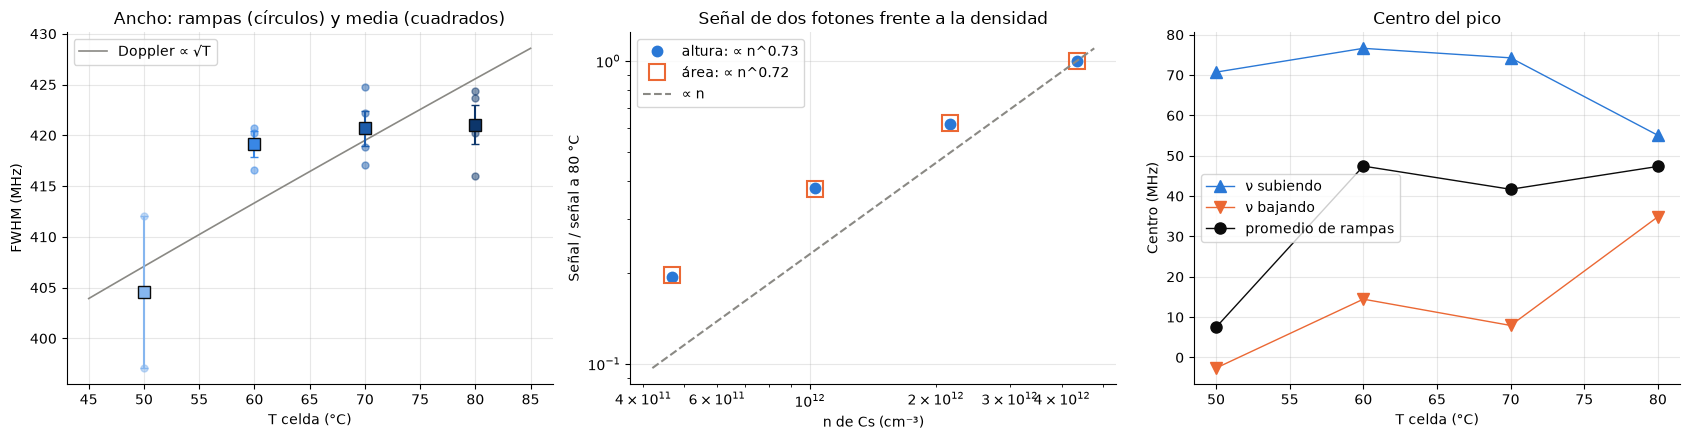

Altura 50 → 60 → 70 → 80 °C: ×1.96, ×1.63, ×1.61  (n: ×2.20, ×2.10, ×2.01)  →  altura ∝ n^0.73


In [5]:
nT = np.array([n_Cs(T) for T in TEMPS])
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))

ax = axs[0]
TT = np.linspace(45, 85, 100)
ax.plot(TT, doppler_fwhm(NU_822, TT), '-', color=GRID, lw=1.2, label='Doppler ∝ √T')
for T, r in res822.items():
    ax.plot(np.full(len(r['fwhm_r']), T), r['fwhm_r'], 'o', ms=5, color=COL_T[T], alpha=0.5)
    ax.errorbar(T, r['fwhm_r'].mean(), yerr=r['fwhm_r'].std(ddof=1)/np.sqrt(len(r['fwhm_r'])), fmt='s', ms=8,
                color=COL_T[T], mec=INK, capsize=3)
ax.set_xlabel('T celda (°C)')
ax.set_ylabel('FWHM (MHz)')
ax.set_title('Ancho: rampas (círculos) y media (cuadrados)')
ax.legend()

ax = axs[1]
for key, mk, txt in (('a', 'o', 'altura'), ('area', 's', 'área')):
    v = np.array([res822[T][key] for T in TEMPS])
    k, lnA = np.polyfit(np.log(nT), np.log(v), 1)
    ax.loglog(nT, v/v[-1], mk, ms=7 if key == 'a' else 12, color=C1 if key == 'a' else C2,
              mfc=None if key == 'a' else 'none', mew=1.5, label=f'{txt}: ∝ n^{k:.2f}')
nn = np.geomspace(nT[0]*0.9, nT[-1]*1.1, 50)
ax.loglog(nn, nn/nT[-1], '--', color=GRID, label='∝ n')
ax.set_xlabel('n de Cs (cm⁻³)')
ax.set_ylabel('Señal / señal a 80 °C')
ax.set_title('Señal de dos fotones frente a la densidad')
ax.legend()

ax = axs[2]
for key, mk, txt in (('up', '^', 'ν subiendo'), ('dn', 'v', 'ν bajando'), ('x0', 'o', 'promedio de rampas')):
    ax.plot(TEMPS, [res822[T][key] for T in TEMPS], mk + '-', ms=8, lw=1, color={'up': C1, 'dn': C2, 'x0': INK}[key],
            label=txt)
ax.set_xlabel('T celda (°C)')
ax.set_ylabel('Centro (MHz)')
ax.set_title('Centro del pico')
ax.legend(loc='best')
fig.tight_layout()
plt.show()

k_a = np.polyfit(np.log(nT), np.log([res822[T]['a'] for T in TEMPS]), 1)[0]
ha = [res822[T]['a'] for T in TEMPS]
print(f"Altura {' → '.join(f'{T:g}' for T in TEMPS)} °C: " + ', '.join(f'×{b/a:.2f}' for a, b in zip(ha, ha[1:]))
      + f"  (n: {', '.join(f'×{b/a:.2f}' for a, b in zip(nT, nT[1:]))})  →  altura ∝ n^{k_a:.2f}")

**Lectura.**

- **Forma:** normalizados, los cuatro picos se superponen. El perfil es Doppler a todas las temperaturas.
- **Ancho:** el FWHM medido rampa por rampa es 404.5 ± 7.5, 419.2 ± 1.3, 420.7 ± 1.7 y 421.1 ± 1.9 MHz a 50, 60, 70 y 80 °C. El Doppler esperado es 407, 413, 420 y 426 MHz.
  - Los anchos coinciden con el Doppler a menos del 1.5 %.
  - El punto de 50 °C es el único por debajo de 419 MHz, pero sale de solo 2 rampas completas, así que su error es grande. Entre 60 y 80 °C el ancho casi no cambia (+2 ± 2 MHz, frente a +12 MHz esperados).
  - El eje de frecuencia tiene sistemáticos del mismo orden que esas diferencias. Por ejemplo, el corrimiento entre rampas de subida y de bajada es de 20 MHz a 80 °C y de 60–75 MHz a 50, 60 y 70 °C. Por eso el ancho no sirve aquí como termómetro.
- **Altura:** crece ×1.96, ×1.63 y ×1.61 en cada paso de 10 °C, contra ×2.20, ×2.10 y ×2.01 de la densidad. En conjunto va como $n^{0.73}$, y el área da el mismo exponente. El paso de 50 a 60 °C es casi proporcional a $n$; los dos siguientes se quedan cortos. Hay dos explicaciones posibles:
  - **(a)** La densidad real crece menos que la calculada con la temperatura nominal, por ejemplo porque un punto frío de la celda fija la presión de vapor.
  - **(b)** La potencia, la frecuencia o la alineación del 822 cambiaron entre tomas.

  La sección 3 da un argumento a favor de (b): la fluorescencia de dos fotones con el 822 fijo no reproduce el máximo de este barrido ni siquiera a la misma temperatura, salvo a 50 y 70 °C.
- **Centro:** el promedio de rampas queda entre 42 y 47 MHz a 60, 70 y 80 °C, pero en 7.5 ± 4.3 MHz a 50 °C. Ese corrimiento de ≈ −40 MHz del medidor de onda reaparece en los valles del 852 a 50 °C (sección 3).

## 2. Barrido del 852 solo

En `fluorescencia.ipynb`, a 80 °C y baja potencia, la línea D2 vista por el PMT tiene dos jorobas con un hueco en el centro. Es autoabsorción: el haz se absorbe antes de llegar a la región que ve el PMT, justo donde la absorción es más fuerte. El modelo es

$$S(\nu) = c + a\, g(\nu)\, e^{-b\, g(\nu)},$$

con $g$ la suma de las tres componentes Doppler F=4 → F′=3, 4, 5 y $b$ la profundidad óptica efectiva hasta la región observada. Como $b \propto n$ a potencia fija (si la saturación no cambia), al bajar la temperatura el hueco debería cerrarse.

Respecto a `fluorescencia.ipynb` hay un cambio: el corrimiento $\nu_0$ se acota a ±250 MHz. Sin esa cota, a 60 °C y 1 mW el ajuste cae en un mínimo sin sentido ($\nu_0 = -676$ MHz, FWHM = 833 MHz). A 80 °C la cota no está activa y los resultados no cambian.

La toma de 200 µW no se ajusta: a 50, 60 y 70 °C la señal (≈ 50–150 cuentas/s) es del orden del ruido entre bins. A 3.5 mW falta 50 °C, porque ese archivo se descartó.

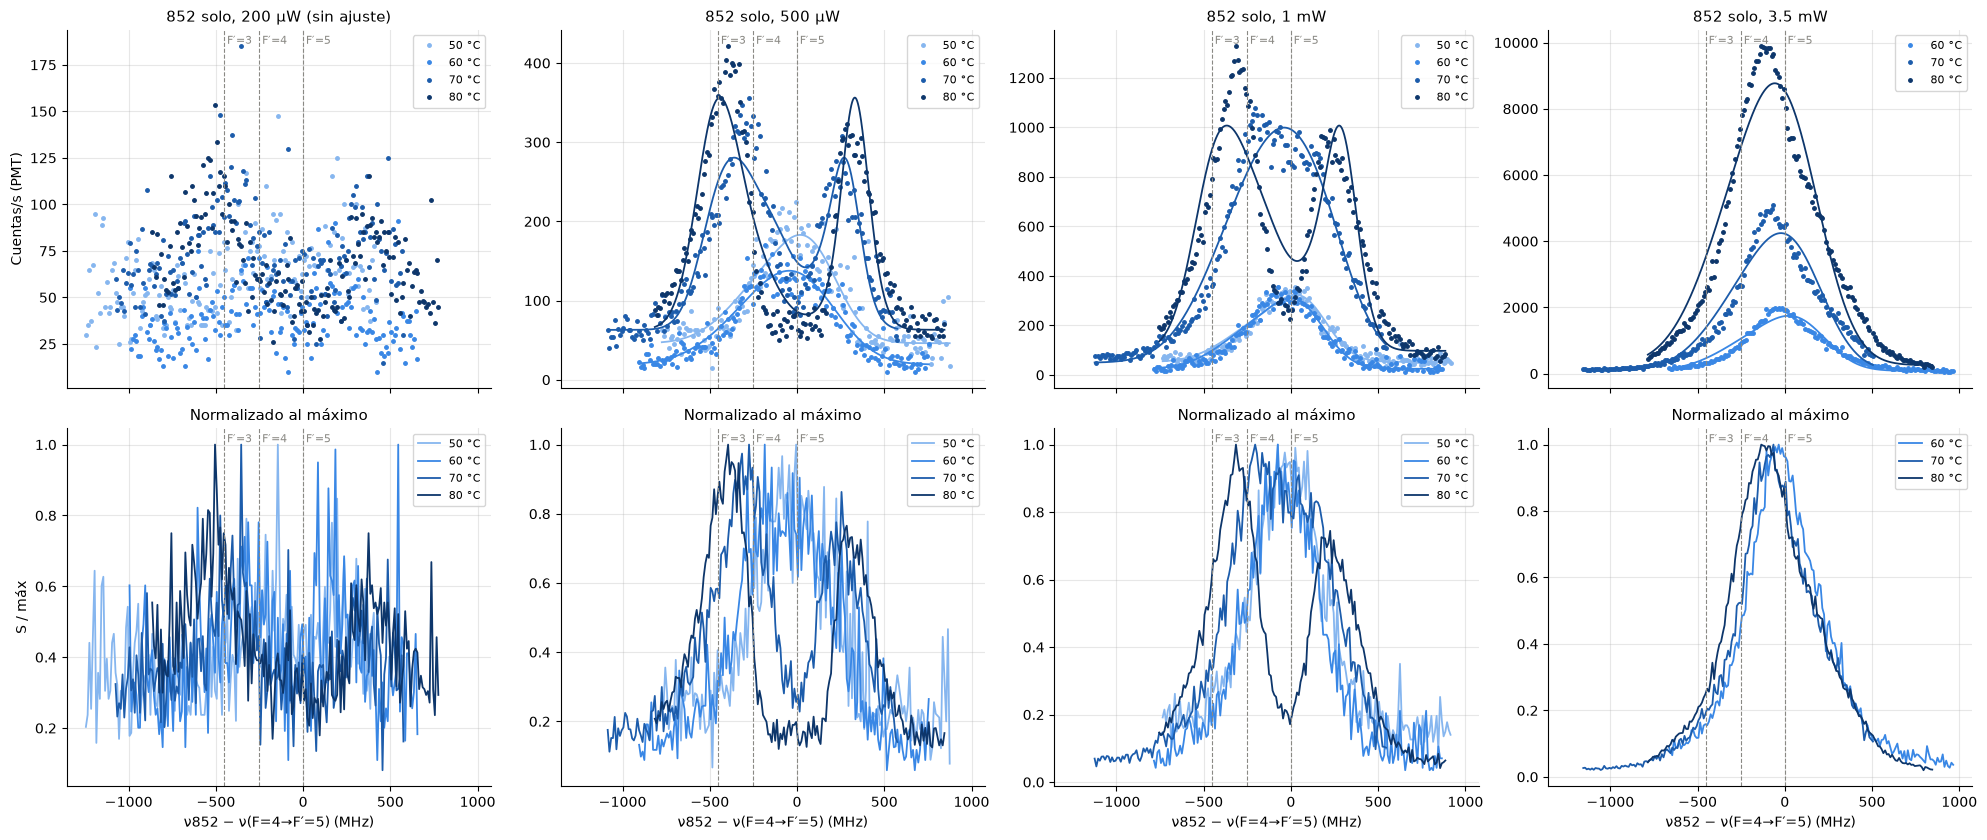

P (mW)    T   ν0 (MHz)   FWHM (MHz)  Doppler            b  máx (c/s)  área (c/s·GHz)  rms/máx
   0.5   50   73 ± 9     397 ± 58        393  0.00 ± 0.23        225           0.079     0.11
   0.5   60   35 ± 7     515 ± 68        399  0.00 ± 0.19        170           0.080     0.08
   0.5   70   75 ± 5     314 ± 11        405  2.89 ± 0.15        356           0.158     0.09
   0.5   80   84 ± 4     327 ± 10        411  4.85 ± 0.29        421           0.171     0.09
   1.0   50   65 ± 4     348 ± 21        393  0.00 ± 0.11        357           0.144     0.07
   1.0   60   42 ± 4     368 ± 22        399  0.00 ± 0.10        355           0.157     0.07
   1.0   70   41 ± 4     526 ± 33        405  0.19 ± 0.09       1078           0.697     0.06
   1.0   80   72 ± 5     342 ± 12        411  2.68 ± 0.14       1328           0.696     0.10
   3.5   60   79 ± 4     405 ± 27        399  0.00 ± 0.11       1998           0.964     0.07
   3.5   70   44 ± 5     446 ± 33        405  0.00 ± 0.12   

In [6]:
W_FP = np.array([11/18, 7/24, 7/72]); W_FP /= W_FP[0]
D_FP = np.array([DET_FP[5], DET_FP[4], DET_FP[3]])

def g852(x, x0, s):
    return sum(w*np.exp(-(x - x0 - dd)**2 / (2*s**2)) for w, dd in zip(W_FP, D_FP))

def selfabs(x, c0, x0, s, a, b):
    g = g852(x, x0, s)
    return c0 + a*g*np.exp(-b*g)

def fit_selfabs(x, y):
    # Varias semillas de b: el ajuste con b grande y con b ~ 0 tiene mínimos locales distintos
    best = None
    for b0 in [0.1, 1, 3, 6, 10]:
        try:
            popt, pcov = curve_fit(selfabs, x, y, p0=[np.percentile(y, 2), 50, 175, y.max(), b0],
                                   bounds=([-np.inf, -250, 30, 0, 0], [np.inf, 250, 600, np.inf, 50]), maxfev=20000)
        except RuntimeError:
            continue
        r = np.sum((y - selfabs(x, *popt))**2)
        if best is None or r < best[0]:
            best = (r, popt, np.sqrt(np.diag(pcov)))
    return best[1], best[2]

P852 = (0.2, 0.5, 1.0, 3.5)
res852 = {}   # (P, T) -> resultados del ajuste
fig, axs = plt.subplots(2, 4, figsize=(20, 8.5), sharex=True)
for j, P in enumerate(P852):
    for T in TEMPS:
        if ('852', P, T) not in DATA:
            continue
        meta, d, segs, x, m, s = scan(DATA[('852', P, T)])
        axs[0, j].plot(x, m, 'o', ms=2.5, color=COL_T[T], label=f'{T:g} °C')
        axs[1, j].plot(x, m/m.max(), '-', lw=1.3, color=COL_T[T], label=f'{T:g} °C')
        if P < 0.3:
            continue
        popt, perr = fit_selfabs(x, m)
        xx = np.linspace(x.min(), x.max(), 2000)
        axs[0, j].plot(xx, selfabs(xx, *popt), '-', color=COL_T[T], lw=1.3)
        res852[(P, T)] = dict(x0=popt[1], ex0=perr[1], fwhm=2.3548*popt[2], efwhm=2.3548*perr[2], b=popt[4],
                              eb=perr[4], c0=popt[0], peak=m.max(), area=np.trapezoid(m - popt[0], x)*1e-6,
                              rms=np.std(m - selfabs(x, *popt))/m.max())
    axs[0, j].set_title(f'852 solo, {label(P)}' + (' (sin ajuste)' if P < 0.3 else ''), fontsize=11)
    axs[1, j].set_title('Normalizado al máximo', fontsize=11)
    for ax in axs[:, j]:
        mark_Fp(ax)
        ax.legend(fontsize=8, loc='upper right')
    axs[1, j].set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
axs[0, 0].set_ylabel('Cuentas/s (PMT)')
axs[1, 0].set_ylabel('S / máx')
fig.tight_layout()
plt.show()

print(f"{'P (mW)':>6s} {'T':>4s} {'ν0 (MHz)':>10s} {'FWHM (MHz)':>12s} {'Doppler':>8s} {'b':>12s} {'máx (c/s)':>10s} "
      f"{'área (c/s·GHz)':>15s} {'rms/máx':>8s}")
for (P, T), r in res852.items():
    print(f"{P:6.1f} {T:4.0f} {r['x0']:4.0f} ± {r['ex0']:<3.0f} {r['fwhm']:5.0f} ± {r['efwhm']:<4.0f} "
          f"{doppler_fwhm(NU_852, T):8.0f} {r['b']:5.2f} ± {r['eb']:<4.2f} {r['peak']:10.0f} {r['area']:15.3f} {r['rms']:8.2f}")

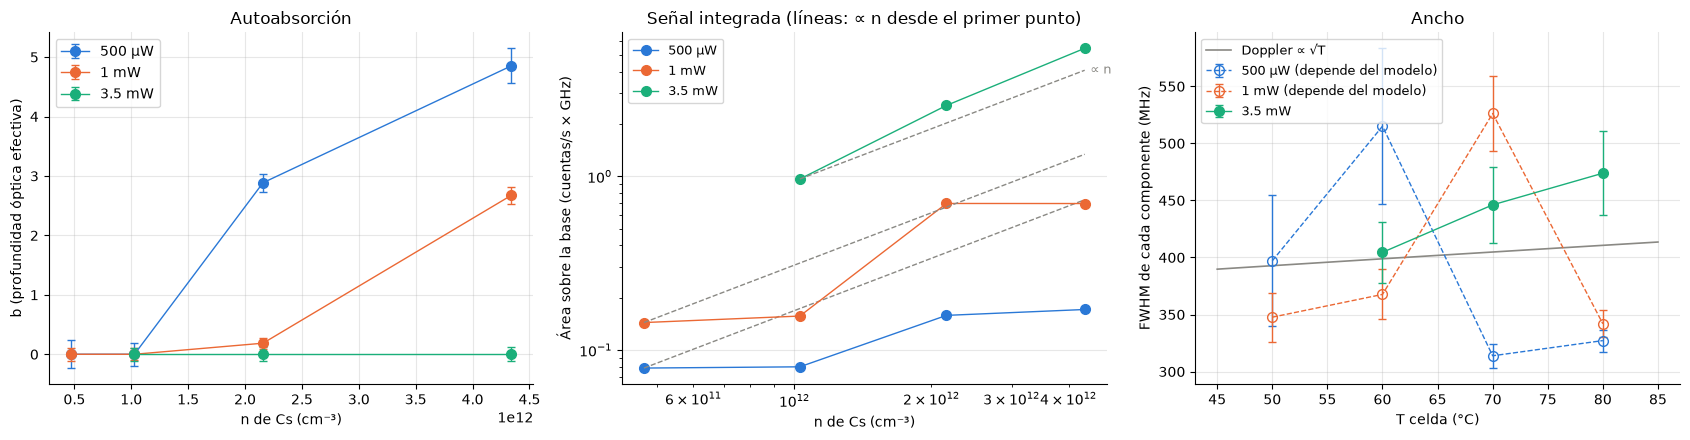

           50→60 °C   60→70 °C   70→80 °C
      n:      ×2.20      ×2.10      ×2.01
 500 µW:      ×1.02      ×1.98      ×1.08
   1 mW:      ×1.09      ×4.44      ×1.00
 3.5 mW:          —      ×2.65      ×2.13
3.5 mW (60–80 °C): área ∝ n^1.20


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
colP = {0.5: C1, 1.0: C2, 3.5: C3}
TP = {P: [T for T in TEMPS if (P, T) in res852] for P in (0.5, 1.0, 3.5)}   # temperaturas con ajuste
nP = {P: np.array([n_Cs(T) for T in TP[P]]) for P in TP}

ax = axs[0]
for P in TP:
    ax.errorbar(nP[P], [res852[(P, T)]['b'] for T in TP[P]], yerr=[res852[(P, T)]['eb'] for T in TP[P]],
                fmt='o-', ms=7, lw=1, color=colP[P], capsize=3, label=label(P))
ax.set_xlabel('n de Cs (cm⁻³)')
ax.set_ylabel('b (profundidad óptica efectiva)')
ax.set_title('Autoabsorción')
ax.legend()

ax = axs[1]
for P in TP:
    v = np.array([res852[(P, T)]['area'] for T in TP[P]])
    ax.loglog(nP[P], v, 'o-', ms=7, lw=1, color=colP[P], label=label(P))
    ax.loglog(nP[P], v[0]*nP[P]/nP[P][0], '--', lw=1, color=GRID)
ax.annotate('∝ n', (nP[3.5][-1], res852[(3.5, TP[3.5][0])]['area']*nP[3.5][-1]/nP[3.5][0]), xytext=(4, 0),
            textcoords='offset points', fontsize=9, color=GRID, va='center')
ax.set_xlabel('n de Cs (cm⁻³)')
ax.set_ylabel('Área sobre la base (cuentas/s × GHz)')
ax.set_title('Señal integrada (líneas: ∝ n desde el primer punto)')
ax.legend(fontsize=9)

ax = axs[2]
ax.plot(TT, doppler_fwhm(NU_852, TT), '-', color=GRID, lw=1.2, label='Doppler ∝ √T')
for P in TP:
    # A P <= 1 mW el ancho depende del modelo de autoabsorción: marcadores huecos
    ax.errorbar(TP[P], [res852[(P, T)]['fwhm'] for T in TP[P]], yerr=[res852[(P, T)]['efwhm'] for T in TP[P]],
                fmt='o' + ('-' if P > 3 else '--'), ms=7, lw=1, color=colP[P], capsize=3,
                mfc=None if P > 3 else 'none', label=label(P) + ('' if P > 3 else ' (depende del modelo)'))
ax.set_xlabel('T celda (°C)')
ax.set_ylabel('FWHM de cada componente (MHz)')
ax.set_title('Ancho')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

# Cociente de áreas entre temperaturas consecutivas, comparado con el de densidades
print(f"{'':>7s}  " + ' '.join(f"{f'{a:g}→{b:g} °C':>10s}" for a, b in zip(TEMPS, TEMPS[1:])))
print(f"{'n':>7s}: " + ' '.join(f"{'×%.2f' % (n_Cs(b)/n_Cs(a)):>10s}" for a, b in zip(TEMPS, TEMPS[1:])))
for P in TP:
    print(f"{label(P):>7s}: " + ' '.join(
        f"{'×%.2f' % (res852[(P, b)]['area']/res852[(P, a)]['area']) if (P, a) in res852 and (P, b) in res852 else '—':>10s}"
        for a, b in zip(TEMPS, TEMPS[1:])))
k35 = np.polyfit(np.log(nP[3.5]), np.log([res852[(3.5, T)]['area'] for T in TP[3.5]]), 1)[0]
print(f"3.5 mW ({TP[3.5][0]:g}–{TP[3.5][-1]:g} °C): área ∝ n^{k35:.2f}")

**Lectura.**

- **Autoabsorción:** el hueco central aparece entre 60 y 70 °C y se profundiza con T, como se espera de una profundidad óptica proporcional a $n$.
  - A 500 µW, $b$ vale 0, 0, 2.9 y 4.9 a 50, 60, 70 y 80 °C.
  - A 1 mW vale 0, 0, 0.2 y 2.7: la saturación compensa parte de la absorción, y a 70 °C el perfil apenas tiene un hueco.
  - A 50 y 60 °C no hay autoabsorción a ninguna potencia. A 3.5 mW no la hay a ninguna temperatura.
  - $b$ no escala como $n$. De 70 a 80 °C, con $n$ ×2.0, crece ×1.7 a 500 µW y ×14 a 1 mW, porque el grado de saturación del medio depende de la propia absorción.
- **Señal integrada:**
  - **3.5 mW (sin autoabsorción, 60–80 °C):** crece ×2.65 y ×2.13, es decir como $n^{1.2}$, más rápido que la fluorescencia de dos fotones del 822 en el mismo intervalo ($n^{0.67}$).
  - **500 µW y 1 mW, de 70 a 80 °C:** casi no crece (×1.08 y ×1.00). La autoabsorción se come lo que gana la densidad.
  - **500 µW y 1 mW, de 50 a 60 °C:** tampoco crece (×1.02 y ×1.09), aunque no hay autoabsorción a ninguna de las dos temperaturas y $n$ se multiplica por 2.2. En el mismo paso, el pico del 822 solo crece ×1.96, así que la densidad sí aumentó. La fluorescencia del 852 solo depende de algo que cambió entre esas tomas, como la potencia o la alineación del 852 en la región observada, y estos datos no dicen qué.
- **Comparación de exponentes:** si la explicación (a) de la sección 1 fuera la correcta, el 822 daría la densidad real, $n_{\rm real} \propto n^{0.67}$ entre 60 y 80 °C. La señal del 852 solo a 3.5 mW iría entonces como $n_{\rm real}^{1.8}$, cerca de $n_{\rm real}^2$. Eso es lo esperable para un proceso entre dos átomos excitados, como las colisiones de *energy pooling* 6P + 6P → 6D, 7P, y concuerda con la dependencia ≈ $P^2$ de `fluorescencia.ipynb`. Con la explicación (b), la señal va como $n^{1.2}$. El paso de 50 a 60 °C a baja potencia, que no crece, muestra que la señal del 852 solo también varía entre tomas, así que este exponente no es una medida firme.
- **Ancho:** a ≤ 1 mW depende del modelo, como ya se vio a 80 °C. A 3.5 mW crece de 405 ± 27 a 474 ± 37 MHz entre 60 y 80 °C. Es una tendencia, no una diferencia significativa.

## 3. Barrido del 852 con el 822 fijo, P ≤ 1 mW

Con el 822 fijo en el máximo de dos fotones, la línea base es la fluorescencia de dos fotones de la clase $v_z \approx 0$. Cuando el 852 es resonante con F=4 → F′ para esa clase, saca átomos de F=4 y aparecen valles sub-Doppler. En `fluorescencia.ipynb` (80 °C) hay valles en F′=3 y F′=4, por bombeo óptico a F=3, y ninguno en F′=5, que es cíclica.

El ajuste es una línea base lineal menos una lorentziana por cada F′. A distintas temperaturas los valles cambian de forma y de profundidad relativa, así que el ajuste de `fluorescencia.ipynb` se generaliza en dos puntos:

- **Semillas:** la de F′=3 es el mínimo de la señal por debajo del punto medio entre F′=3 y F′=4, no el mínimo global. Así no se confunde con F′=4 cuando ambos valles tienen la misma profundidad. Las de F′=4 y F′=5 van a las separaciones tabuladas, y cada centro queda acotado a ±60 MHz de su semilla.
- **F′=5:** se incluye un tercer valle. Se descarta el menos significativo de F′=4 y F′=5 si su profundidad es menor que 3σ, y se vuelve a ajustar.

Como la potencia o la frecuencia del 822 pueden cambiar de una toma a otra, la profundidad de cada valle se da relativa a la línea base en esa misma frecuencia.

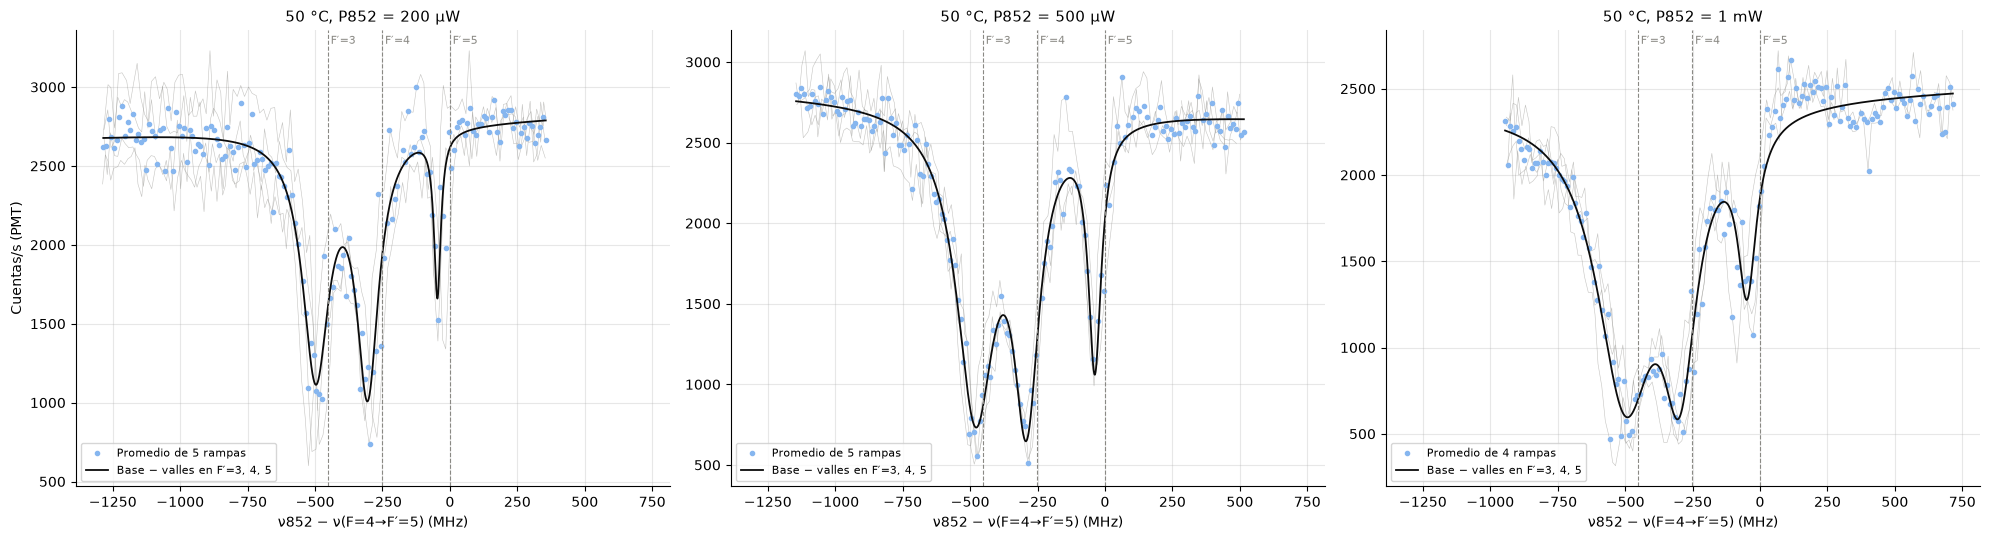

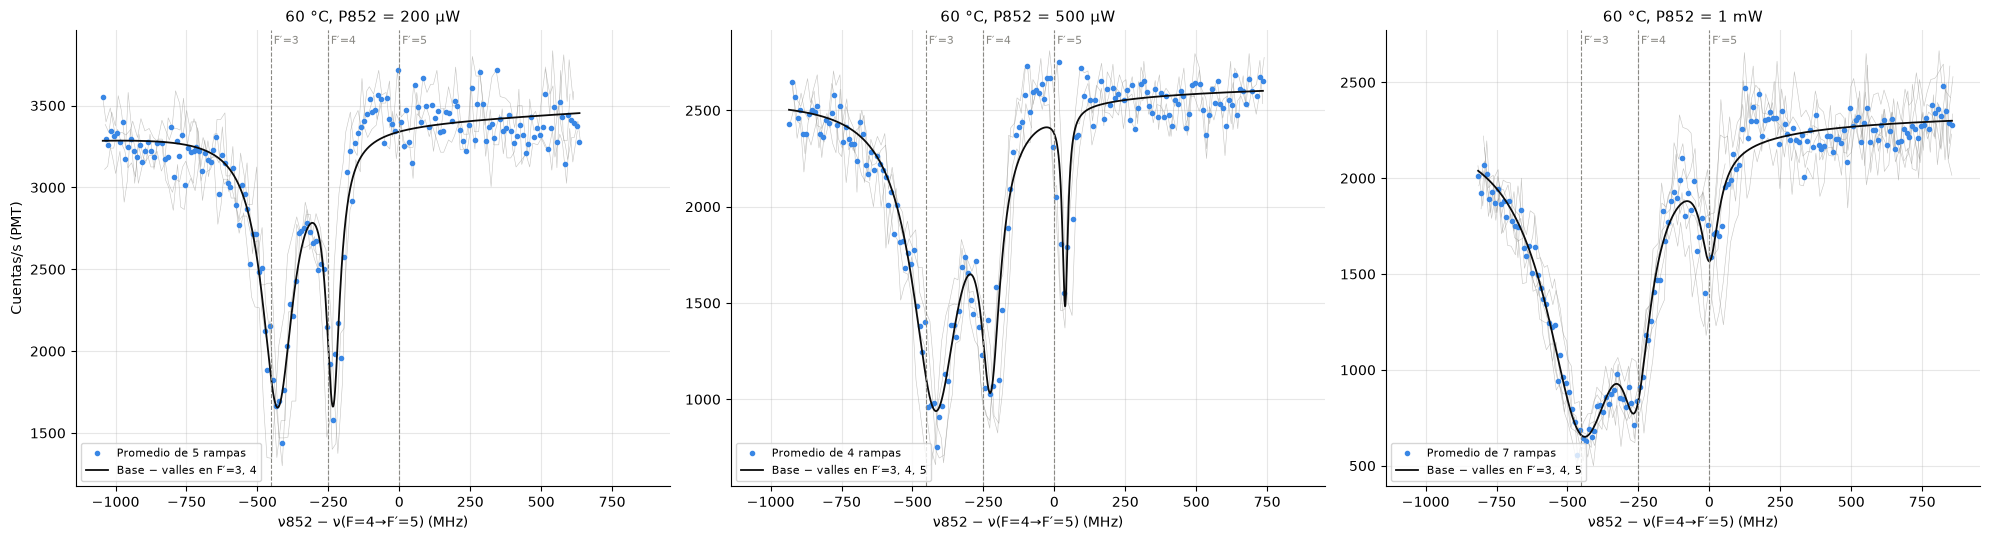

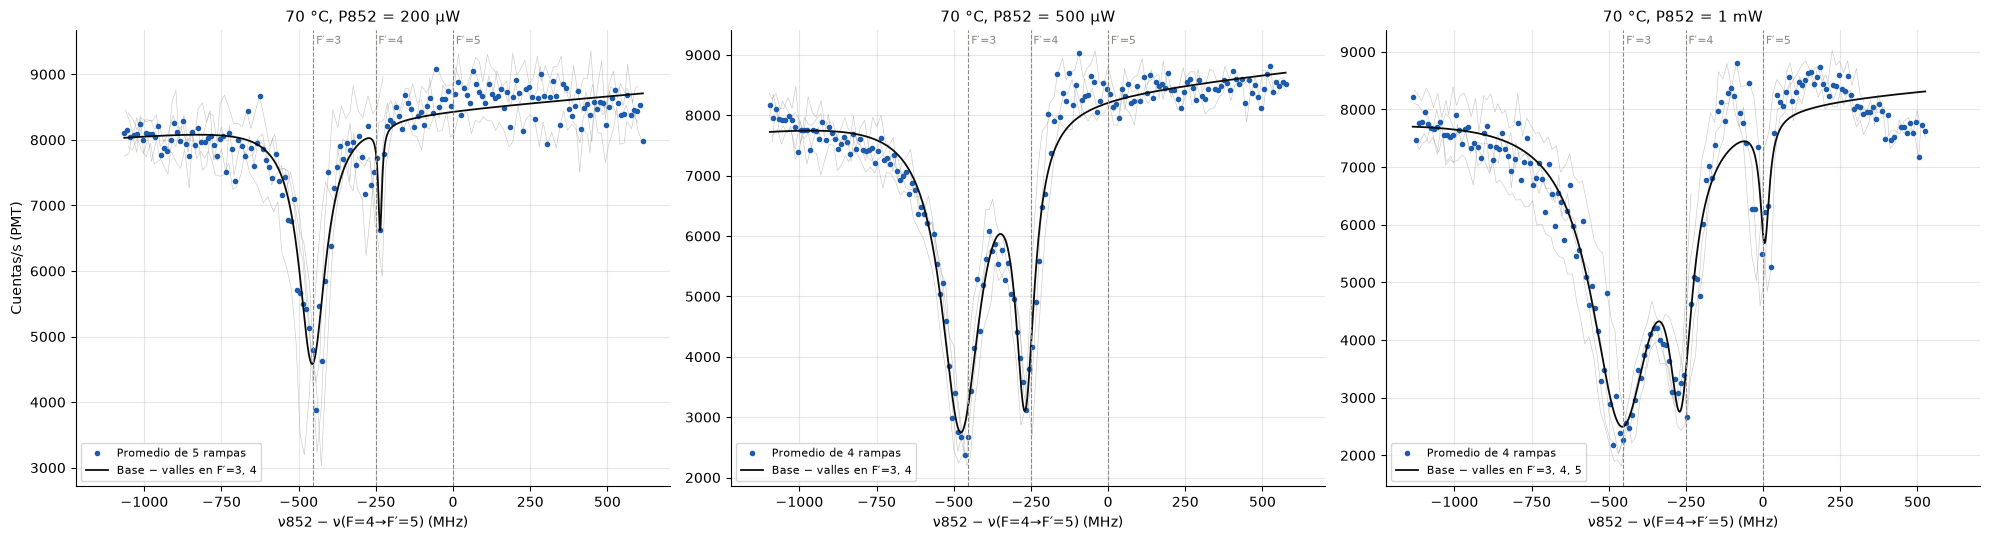

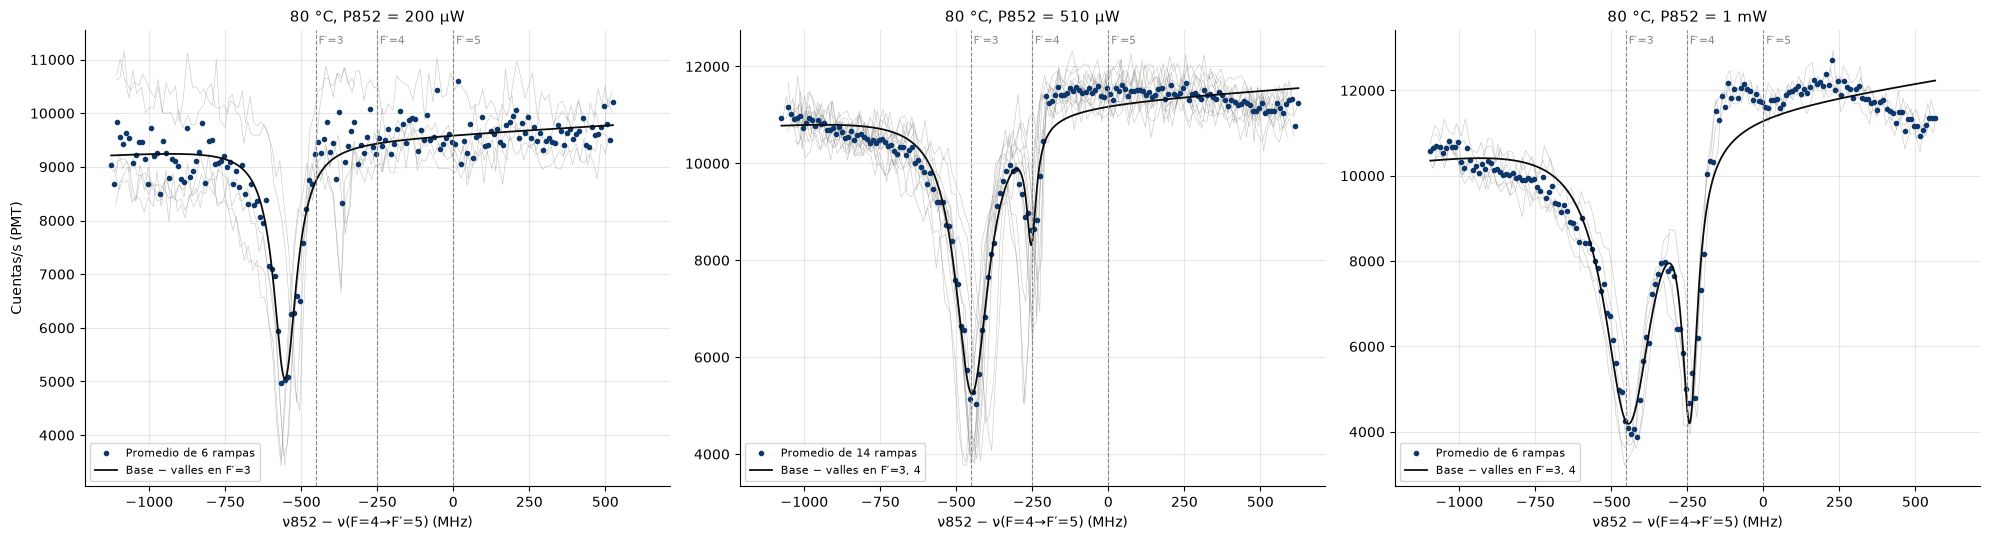

P (mW)    T base (c/s) |              F′=3               |              F′=4               |              F′=5              
                       |    centro      FWHM  prof./base |    centro      FWHM  prof./base |    centro      FWHM  prof./base
   0.2   50       2781 |  -498 ± 3   120 ± 11  0.56 ± 0.03 |  -305 ± 3    99 ± 9   0.58 ± 0.03 |   -46 ± 2    31 ± 6   0.37 ± 0.05
   0.5   50       2710 |  -480 ± 2   172 ± 8   0.68 ± 0.02 |  -291 ± 2   115 ± 7   0.64 ± 0.02 |   -38 ± 1    58 ± 5   0.55 ± 0.04
   1.0   50       2461 |  -500 ± 7   261 ± 24  0.68 ± 0.03 |  -298 ± 5   155 ± 18  0.55 ± 0.03 |   -48 ± 4    83 ± 12  0.38 ± 0.03
   0.2   60       3403 |  -429 ± 3   134 ± 9   0.50 ± 0.02 |  -233 ± 2    58 ± 6   0.46 ± 0.03 |                —               
   0.5   60       2593 |  -419 ± 4   200 ± 14  0.62 ± 0.02 |  -225 ± 3    82 ± 10  0.47 ± 0.03 |    38 ± 2    24 ± 6   0.39 ± 0.06
   1.0   60       2310 |  -446 ± 6   318 ± 25  0.68 ± 0.02 |  -259 ± 4   119 ± 16  0.37 ± 0.03 | 

In [8]:
def lorentz(x, x0, g, a):
    return a*(g/2)**2 / ((x - x0)**2 + (g/2)**2)

def dips(x, c0, c1, *p):
    return c0 + c1*x*1e-3 - sum(lorentz(x, *p[i:i + 3]) for i in range(0, len(p), 3))

SEP = {F: DET_FP[F] - DET_FP[3] for F in (3, 4, 5)}

def fit_dips(x, y, Fs=(3, 4, 5), win=60):
    # Base lineal menos una lorentziana por F'. Devuelve los F' que quedaron, popt y perr
    ys = uniform_filter1d(y, 3)
    lo = np.flatnonzero(x < (DET_FP[3] + DET_FP[4])/2 + 30)
    k = lo[np.argmin(ys[lo])]
    c0 = np.percentile(y, 90)
    Fs = list(Fs)
    while True:
        p0, lb, ub = [c0, 0], [-np.inf, -np.inf], [np.inf, np.inf]
        for F in Fs:
            xc = x[k] + SEP[F]
            p0 += [xc, 50, (c0 - y[k])*(1 if F == 3 else 0.3)]
            lb += [xc - win, 5, 0]
            ub += [xc + win, 500, np.inf]
        try:
            popt, pcov = curve_fit(dips, x, y, p0=p0, bounds=(lb, ub), maxfev=20000)
        except RuntimeError:
            # Sin convergencia: pasa cuando un valle no existe y su amplitud queda en 0. Se descarta el de mayor F'
            Fs.remove(max(F for F in Fs if F != 3))
            continue
        perr = np.sqrt(np.diag(pcov))
        sig = {F: popt[4 + 3*i]/perr[4 + 3*i] for i, F in enumerate(Fs) if F != 3}
        if not sig or min(sig.values()) >= 3:
            return Fs, popt, perr
        Fs.remove(min(sig, key=sig.get))

def dip_params(Fs, popt, perr):
    # {x3, ex3, g3, eg3, a3, ea3, r3, er3, ...}; r = profundidad / base en el centro del valle. NaN si no se resolvió
    out = dict(c0=popt[0], c1=popt[1])
    for F in (3, 4, 5):
        if F in Fs:
            i = 2 + 3*Fs.index(F)
            base = popt[0] + popt[1]*popt[i]*1e-3
            vals = dict(x=popt[i], g=popt[i + 1], a=popt[i + 2], r=popt[i + 2]/base)
            errs = dict(x=perr[i], g=perr[i + 1], a=perr[i + 2], r=perr[i + 2]/base)
        else:
            vals = errs = dict(x=np.nan, g=np.nan, a=np.nan, r=np.nan)
        for k in vals:
            out[f'{k}{F}'], out[f'e{k}{F}'] = vals[k], errs[k]
    return out

PCOMB = (0.2, 0.5, 1.0)
resdip = {}   # (P, T) -> parámetros de los valles
for T in TEMPS:
    # Una figura por temperatura, con un panel por potencia
    fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), sharex=True)
    for ax, P in zip(axs, PCOMB):
        meta, d, segs, x, m, s = scan(DATA[('852+822', P, T)])
        for sg in segs:
            ax.plot(d['det'][sg], d['A'][sg], '-', lw=0.4, color=GRID, alpha=0.5)
        ax.plot(x, m, 'o', ms=3, color=COL_T[T], label=f'Promedio de {len(segs)} rampas')
        Fs, popt, perr = fit_dips(x, m)
        xx = np.linspace(x.min(), x.max(), 2000)
        ax.plot(xx, dips(xx, *popt), '-', color=INK, lw=1.3,
                label=f"Base − valles en F′={', '.join(map(str, Fs))}")
        resdip[(P, T)] = dict(P_real=meta['P'], Fs=Fs, **dip_params(Fs, popt, perr))
        mark_Fp(ax)
        ax.set_title(f"{T:g} °C, P852 = {label(meta['P'])}", fontsize=11)
        ax.legend(fontsize=8, loc='lower left')
        ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
    axs[0].set_ylabel('Cuentas/s (PMT)')
    fig.tight_layout()
    plt.show()

def fmt_dip(r, F):
    if np.isnan(r[f'x{F}']):
        return f"{'—':^31s}"
    return (f"{r[f'x{F}']:5.0f} ± {r[f'ex{F}']:<3.0f}{r[f'g{F}']:4.0f} ± {r[f'eg{F}']:<3.0f}"
            f"{r[f'r{F}']:5.2f} ± {r[f'er{F}']:<4.2f}")
hdr = f"{'centro':>9s} {'FWHM':>9s} {'prof./base':>11s}"
print(f"{'P (mW)':>6s} {'T':>4s} {'base (c/s)':>10s} | {'F′=3':^31s} | {'F′=4':^31s} | {'F′=5':^31s}")
print(f"{'':6s} {'':4s} {'':10s} | {hdr} | {hdr} | {hdr}")
for (P, T), r in resdip.items():
    print(f"{P:6.1f} {T:4.0f} {r['c0']:10.0f} | {fmt_dip(r, 3)} | {fmt_dip(r, 4)} | {fmt_dip(r, 5)}")
print(f"Tabulado: F′=3 en {DET_FP[3]:.1f} MHz, F′=4 en {DET_FP[4]:.1f} MHz, F′=5 en 0 MHz")

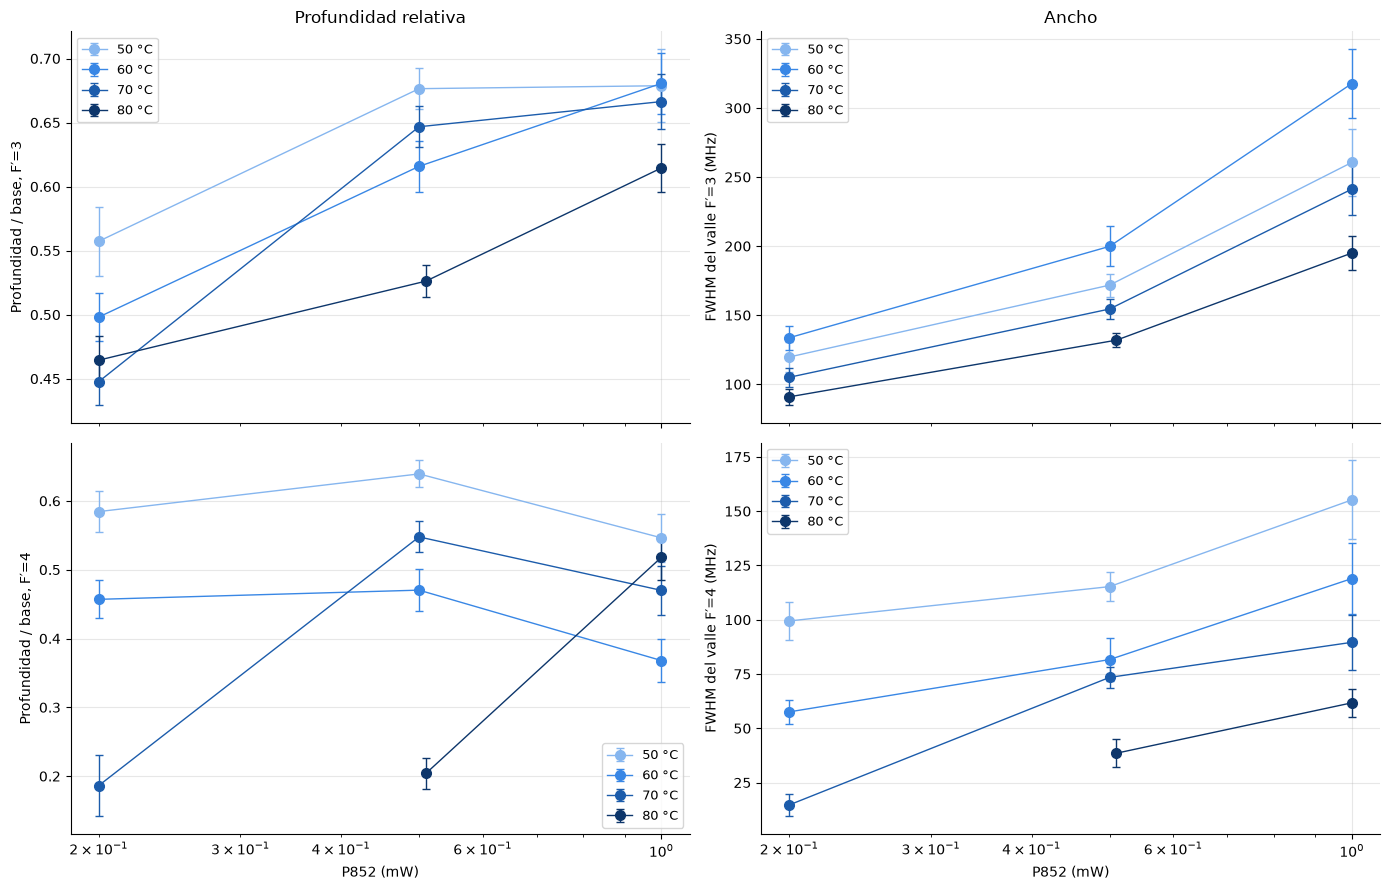

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for i, F in enumerate((3, 4)):
    for T in TEMPS:
        rr = [resdip[(P, T)] for P in PCOMB]
        Pr = np.array([r['P_real'] for r in rr])
        for j, key in enumerate(('r', 'g')):
            axs[i, j].errorbar(Pr, [r[f'{key}{F}'] for r in rr], yerr=[r[f'e{key}{F}'] for r in rr], fmt='o-', ms=7,
                               lw=1, color=COL_T[T], capsize=3, label=f'{T:g} °C')
    axs[i, 0].set_ylabel(f'Profundidad / base, F′={F}')
    axs[i, 1].set_ylabel(f'FWHM del valle F′={F} (MHz)')
axs[0, 0].set_title('Profundidad relativa')
axs[0, 1].set_title('Ancho')
for ax in axs.flat:
    ax.set_xscale('log')
    ax.legend(fontsize=9)
for ax in axs[-1]:
    ax.set_xlabel('P852 (mW)')
fig.tight_layout()
plt.show()

### Posición de los valles y frecuencia del 822

Si el 822 está a $\delta_1$ del máximo de dos fotones, selecciona la clase $v_z = c\,\delta_1/\nu_{822}$, y los valles se corren en $\delta_1\,\nu_{852}/\nu_{822}$. El corrimiento de cada valle respecto a su valor tabulado da entonces la $\delta_1$ que haría falta en cada toma.

La línea base da una segunda estimación, independiente. Lejos de los valles es la fluorescencia de dos fotones con el 822 fijo. Si la potencia y la alineación del 822 fueran las del barrido del 822 solo a la misma temperatura, el cociente entre la base y el máximo de ese barrido sería $e^{-\delta_1^2/2\sigma^2}$, con $\sigma$ el ancho del pico de dos fotones.

P (mW)    T   Δx F′=3   Δx F′=4  δ1 valles (MHz)  base/máx 822 solo
   0.2   50       -45       -54              -51               1.05
   0.5   50       -28       -40              -35               1.05
   1.0   50       -47       -47              -49               0.93
   0.2   60        23        18               21               0.66
   0.5   60        34        26               31               0.51
   1.0   60         7        -8               -1               0.45
   0.2   70        -4        15                6               1.00
   0.5   70       -25       -18              -22               0.99
   1.0   70        -6       -16              -12               0.98
   0.2   80      -101         —             -105               0.71
   0.5   80         4        -2                1               0.83
   1.0   80         9         9                9               0.84


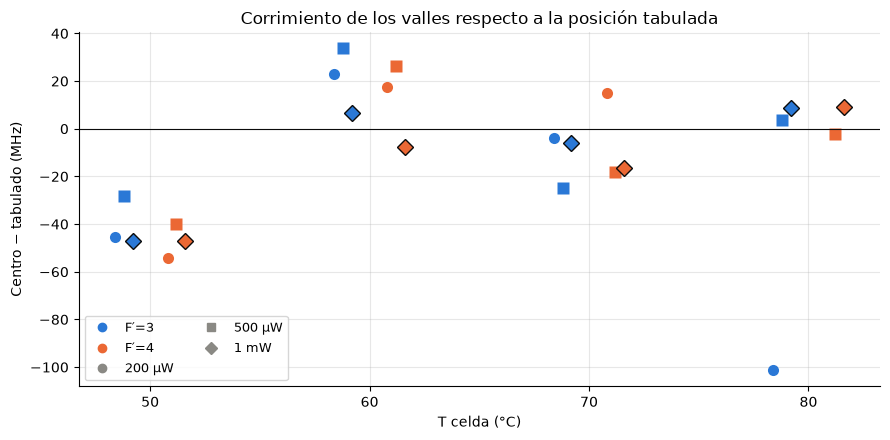

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
mk = {0.2: 'o', 0.5: 's', 1.0: 'D'}
print(f"{'P (mW)':>6s} {'T':>4s} {'Δx F′=3':>9s} {'Δx F′=4':>9s} {'δ1 valles (MHz)':>16s} {'base/máx 822 solo':>18s}")
for (P, T), r in resdip.items():
    dx = np.array([r[f'x{F}'] - DET_FP[F] for F in (3, 4)])
    d1 = np.nanmean(dx)*NU_822/NU_852
    ratio = (r['c0'] + r['c1']*DET_FP[3]*1e-3) / (res822[T]['a'] + res822[T]['c0'])
    r.update(d1=d1, ratio=ratio)
    for F, dxF, dT in ((3, dx[0], -1.2), (4, dx[1], 1.2)):
        if not np.isnan(dxF):
            ax.plot(T + dT + (PCOMB.index(P) - 1)*0.4, dxF, mk[P], ms=8, color=C1 if F == 3 else C2,
                    mec=INK if P == 1.0 else 'none')
    print(f"{P:6.1f} {T:4.0f} " + ' '.join(f"{v:9.0f}" if not np.isnan(v) else f"{'—':>9s}" for v in dx)
          + f" {d1:16.0f} {ratio:18.2f}")
for F, col in ((3, C1), (4, C2)):
    ax.plot([], [], 'o', color=col, label=f'F′={F}')
for P in PCOMB:
    ax.plot([], [], mk[P], color=GRID, label=label(P))
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(TEMPS)
ax.set_xlabel('T celda (°C)')
ax.set_ylabel('Centro − tabulado (MHz)')
ax.set_title('Corrimiento de los valles respecto a la posición tabulada')
ax.legend(ncol=2, fontsize=9, loc='lower left')
fig.tight_layout()
plt.show()

**Lectura.**

- **El 852 que llega a la región observada:** la mayor parte de lo que cambia con T en esta serie se entiende con una sola idea. A mayor T el 852 se absorbe más antes de llegar a la región que ve el PMT (sección 2), así que a la misma potencia de entrada los átomos observados ven menos intensidad. Eso se ve en tres cosas:
  - **Valle en F′=5:** a 80 °C no aparece nunca. A 70 °C aparece solo a 1 mW, a 60 °C a 500 µW y 1 mW, y a 50 °C a las tres potencias, con profundidad relativa de 0.23 a 0.55. Cuanto más fría la celda, menos potencia hace falta. F′=5 es cíclica, así que no hay bombeo a F=3. El valle aparece cuando el 852 llega con intensidad suficiente para saturar la transición y mantener en 6P3/2 una fracción apreciable de la clase $v_z \approx 0$, que deja de estar disponible en 6S F=4 para el 822.
  - **Ancho de F′=4:** a cada potencia crece al enfriar la celda. A 1 mW mide 62, 90, 119 y 155 MHz a 80, 70, 60 y 50 °C; a 500 µW, 39, 73, 82 y 115 MHz.
  - **Ancho de F′=3:** de 80 a 60 °C también crece al enfriar (a 1 mW, 195, 241 y 318 MHz; a 200 µW, 91, 105 y 134 MHz). A 60 °C con 200 µW el valle es tan ancho como a 80 °C con 500 µW. A 50 °C, en cambio, queda entre 60 y 70 °C (261 MHz a 1 mW). Entre 50 y 60 °C no hay autoabsorción apreciable (sección 2), así que la intensidad local no debería cambiar mucho. La diferencia de 10–20 % está dentro de lo que varía la señal del 852 entre tomas (sección 2, paso de 50 a 60 °C).
  - **Fusión de F′=3 y F′=4:** a 60 °C y 1 mW los dos valles se solapan en un único valle ancho entre ≈ −600 y −200 MHz. A 50 °C y 1 mW están casi tan solapados.
- **Profundidad relativa de F′=3:** sube con la potencia a todas las temperaturas. A 500 µW y 1 mW la de 80 °C (0.53 y 0.61) queda por debajo de las de 50, 60 y 70 °C (0.62–0.68), que casi no cambian entre sí.
- **Profundidad de F′=4:** a 50 °C es la mayor (0.55–0.64), comparable a la de F′=3. A 70 y 80 °C varía mucho (0.19–0.55). Los valores bajos corresponden a los valles más angostos (15 MHz a 70 °C y 200 µW, 39 MHz a 80 °C y 500 µW), comparables al desplazamiento entre rampas del eje de frecuencia (20–75 MHz entre subida y bajada en el barrido del 822). Ahí el promedio de rampas achica el valle.
- **Robustez:** restar el barrido del 852 solo antes de ajustar, como en la sección 4, cambia la profundidad relativa de F′=3 en ≤ 0.07 y su ancho en ≤ 20 MHz. El orden con T no cambia.
- **Frecuencia del 822 y cero del medidor de onda:**
  - A 60, 70 y 80 °C, salvo la toma de 200 µW a 80 °C (δ1 ≈ −105 MHz, ya señalada en `fluorescencia.ipynb`), los valles dan |δ1| ≤ 31 MHz.
  - A 50 °C los valles se corren de −28 a −54 MHz, es decir δ1 ≈ −35 a −51 MHz. Pero la línea base está al 93–105 % del máximo del 822 solo, que con esa δ1 debería ser ≈ 97 %, así que el 822 estaba en el máximo de dos fotones igual que en las demás tomas. El barrido del 822 solo de esa temperatura tiene su centro ≈ 40 MHz más abajo que los demás (sección 1). Lo más simple es que ese día el cero del medidor de onda estuviera corrido ≈ −40 MHz para los dos láseres, y que el corrimiento de los valles venga de ahí y no de una desintonía del 822.
  - Con |δ1| ≤ 31 MHz, la línea base debería quedar a más del 98 % del máximo del 822 solo. Eso se cumple a 50 y 70 °C (0.93–1.05), pero a 60 °C queda en 0.45–0.66 y a 80 °C en 0.71–0.84. La potencia o la alineación del 822 cambiaron entre el barrido del 822 solo y estas tomas en hasta un factor 2. Es el argumento a favor de la explicación (b) de la sección 1: la altura absoluta del pico de dos fotones no es reproducible de una toma a otra, y las comparaciones entre temperaturas deben hacerse con magnitudes relativas.

## 4. Con y sin 822 a 3.5 mW

A 3.5 mW domina la fluorescencia que produce el 852 por sí solo, así que, como en `fluorescencia.ipynb`, se le resta el barrido del 852 solo de la misma potencia y temperatura:

$$\Delta S(\nu_{852}) = S_{822+852} - S_{852}.$$

Solo hay 60 y 80 °C. El archivo de 70 °C no tiene lecturas del 852. A 50 °C, la toma combinada probablemente es el archivo rotulado como 852 solo, y no hay un barrido del 852 solo a 3.5 mW de esa temperatura para restarle. Para comparar las dos temperaturas, $\Delta S$ se normaliza por su valor lejos de la resonancia (mediana para ν > +500 MHz).

ΔS / ΔS(ν > 500 MHz), promedio en cada ventana (MHz):
   T  lejos (c/s)       F′=3       F′=4       F′=5  +200…+300
  60         4268       0.14       0.14       0.33       0.82
  80         8540       0.15       0.38       0.75       0.96


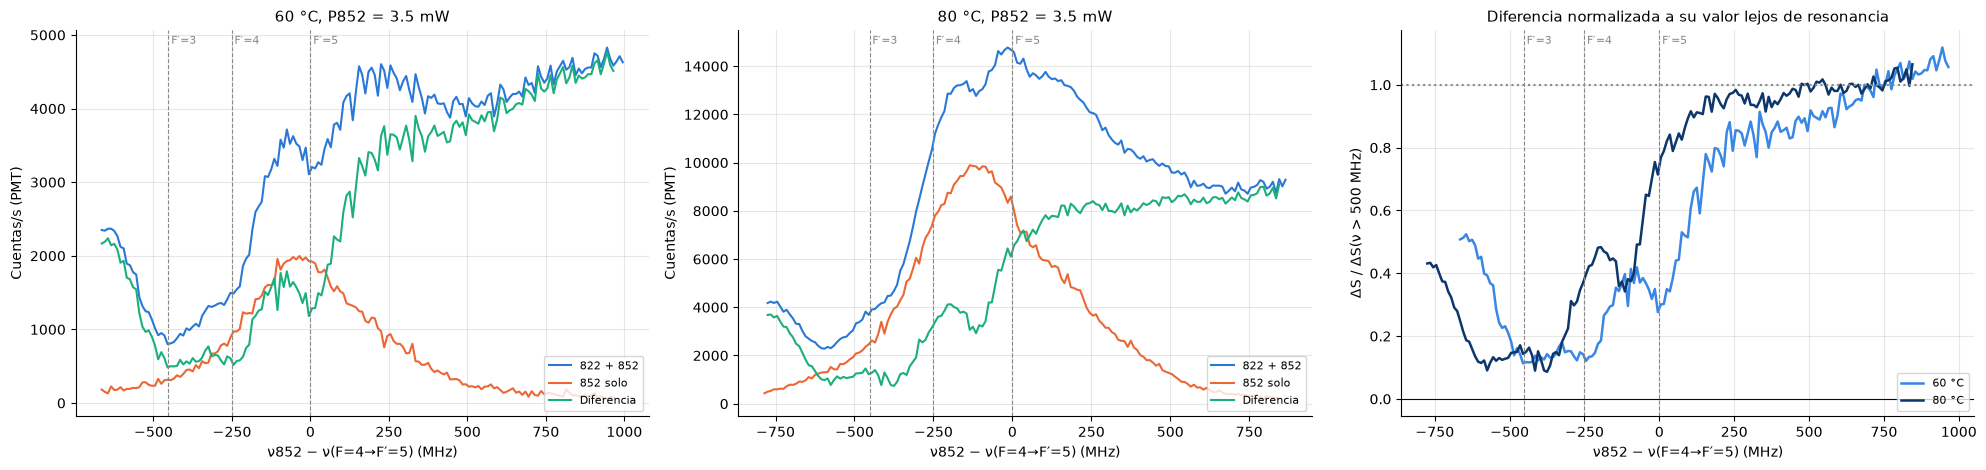

In [11]:
WIN = {"F′=3": (-500, -400), "F′=4": (-300, -200), "F′=5": (-50, 50), "+200…+300": (200, 300)}
print(f"ΔS / ΔS(ν > 500 MHz), promedio en cada ventana (MHz):")
print(f"{'T':>4s} {'lejos (c/s)':>12s} " + ' '.join(f"{k:>10s}" for k in WIN))
fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, T in zip(axs, (60.0, 80.0)):
    _, _, _, x, m, _ = scan(DATA[('852+822', 3.5, T)])
    _, _, _, xs, ms, _ = scan(DATA[('852', 3.5, T)])
    ov = (x >= xs.min()) & (x <= xs.max())
    dS = m[ov] - np.interp(x[ov], xs, ms)
    far = np.median(dS[x[ov] > 500])
    ax.plot(x, m, '-', lw=1.5, color=C1, label='822 + 852')
    ax.plot(xs, ms, '-', lw=1.5, color=C2, label='852 solo')
    ax.plot(x[ov], dS, '-', lw=1.5, color=C3, label='Diferencia')
    ax.set_title(f'{T:g} °C, P852 = 3.5 mW', fontsize=11)
    ax.set_ylabel('Cuentas/s (PMT)')
    axs[2].plot(x[ov], dS/far, '-', lw=1.8, color=COL_T[T], label=f'{T:g} °C')
    print(f"{T:4.0f} {far:12.0f} " + ' '.join(f"{np.mean(dS[(x[ov] >= a) & (x[ov] <= b)])/far:10.2f}"
                                             for a, b in WIN.values()))
axs[2].axhline(1, ls=':', color=GRID)
axs[2].axhline(0, color=INK, lw=0.8)
axs[2].set_title('Diferencia normalizada a su valor lejos de resonancia', fontsize=11)
axs[2].set_ylabel('ΔS / ΔS(ν > 500 MHz)')
for ax in axs:
    mark_Fp(ax)
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
    ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

**Lectura.** A las dos temperaturas, la fluorescencia de dos fotones queda suprimida en F′=3 hasta ≈ 15 % de su valor lejos de resonancia. La diferencia está en el ancho de la zona suprimida:

| Ventana | 60 °C | 80 °C |
|---|---|---|
| F′=4 | 0.14 | 0.38 |
| F′=5 | 0.33 | 0.75 |
| +200 a +300 MHz | 0.82 | 0.96 |

A 60 °C la supresión cubre F′=4 tan a fondo como F′=3 y llega hasta F′=5. Es el mismo efecto que en los valles de baja potencia: con la celda más fría, el 852 llega con más intensidad a la región observada y vacía F=4 en un intervalo de frecuencias más ancho. Esta lectura supone, como en `fluorescencia.ipynb`, que las contribuciones con y sin 822 se suman.

## Resumen

- **Densidad:** con la fórmula de presión de vapor, $n$ se multiplica por 9.3 entre 50 y 80 °C (de $4.7\times10^{11}$ a $4.3\times10^{12}$ cm⁻³). Ninguna señal sigue exactamente ese factor.
- **822 solo:**
  - El perfil es Doppler a todas las temperaturas, con FWHM de 405 a 421 MHz (rampa por rampa).
  - El aumento con $\sqrt{T}$ no se resuelve: el punto de 50 °C tiene un error grande y entre 60 y 80 °C el ancho no cambia. Los sistemáticos del eje de frecuencia son del orden de 10 MHz.
  - La altura crece como $n^{0.73}$: ×5.2 entre 50 y 80 °C en lugar de ×9.3. La potencia o la alineación del 822 cambian entre tomas hasta un factor 2 (lo muestra la línea base de la serie 852 + 822), así que la altura absoluta no es una medida fiable de $n$.
  - A 50 °C el centro del pico, y con él el cero del medidor de onda, está ≈ 40 MHz más abajo que en las demás tomas.
- **852 solo:**
  - La autoabsorción aparece entre 60 y 70 °C. A 50 y 60 °C ninguna potencia muestra el hueco central; a 500 µW, $b$ vale 0, 0, 2.9 y 4.9 a 50, 60, 70 y 80 °C.
  - A 3.5 mW, sin autoabsorción, la señal integrada crece como $n^{1.2}$ entre 60 y 80 °C, más rápido que la del 822.
  - A 500 µW y 1 mW la señal no crece ni entre 50 y 60 °C (sin autoabsorción y con $n$ ×2.2) ni entre 70 y 80 °C (donde la autoabsorción compensa). El primer caso indica que la señal del 852 solo también varía entre tomas.
- **852 con el 822 fijo, ≤ 1 mW:** la temperatura actúa sobre todo a través de la intensidad del 852 que llega a la región observada, que baja al subir T por la absorción previa.
  - El valle en F′=5, la transición cíclica, aparece por saturación con menos potencia cuanto más fría está la celda: a 50 °C a las tres potencias, a 60 °C desde 500 µW, a 70 °C solo a 1 mW y a 80 °C nunca.
  - El valle F′=4 se ensancha al enfriar a todas las potencias (a 1 mW, 62, 90, 119 y 155 MHz de 80 a 50 °C). F′=3 también se ensancha de 80 a 60 °C (195, 241 y 318 MHz a 1 mW), pero a 50 °C queda en 261 MHz.
  - A 60 °C y 1 mW los valles F′=3 y F′=4 se funden, y a 50 °C casi.
  - A 60, 70 y 80 °C las posiciones de los valles dan |δ1| ≤ 31 MHz, salvo a 200 µW y 80 °C (−105 MHz). A 50 °C se corren ≈ −45 MHz, lo que se explica por el corrimiento del medidor de onda y no por una desintonía del 822.
- **852 con el 822 fijo, 3.5 mW:** al restar el 852 solo, la zona sin fluorescencia de dos fotones es más ancha a 60 °C que a 80 °C. En F′=4 queda al 14 % frente al 38 % de su valor lejos de resonancia, y en F′=5 al 33 % frente al 75 %.
- **Datos descartados:**
  - `852-0MHz-3.5mW-46mW-20mHz-200ms-70C.txt` contiene un barrido del 822 (λ 822.4642…822.4695 nm), no del 852.
  - `852-3.5mW-20mHz-200ms-50C.txt` se tomó con el 822 encendido aunque el nombre diga 852 solo: su nivel lejos de resonancia, ≈ 2300 cuentas/s, es el de la fluorescencia de dos fotones.